In [1]:
import pandas as pd
import os
import zipfile

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".zip"):
            with zipfile.ZipFile(os.path.join(root, file)) as z:
                z.extractall("/kaggle/working")

for folder in ["/kaggle/input", "/kaggle/working"]:
    for root, dirs, files in os.walk(folder):
        if "student-mat.csv" in files:
            df = pd.read_csv(
                os.path.join(root, "student-mat.csv"),
                sep=None,
                engine="python"
            )

print("Student Performance Analysis")
print("Dataset size:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())

Student Performance Analysis
Dataset size: (395, 33)
Missing values: 0
Duplicate rows: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


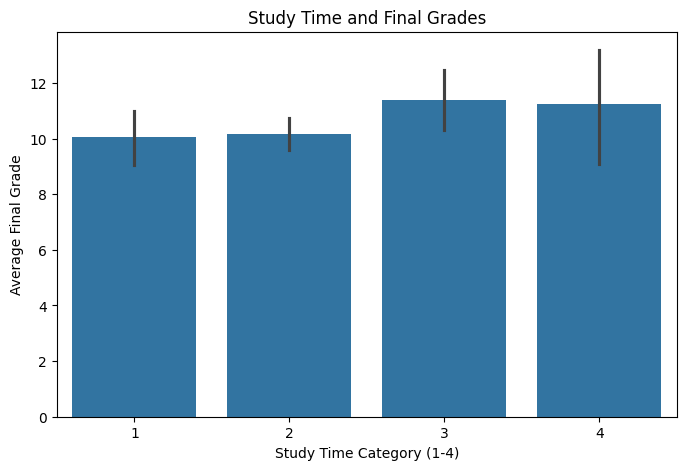

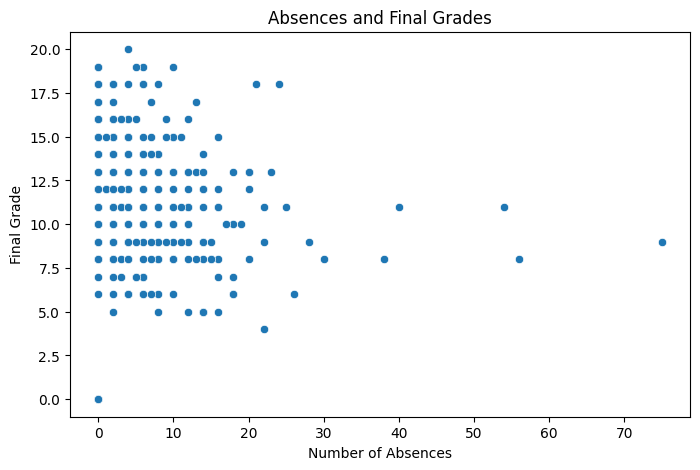

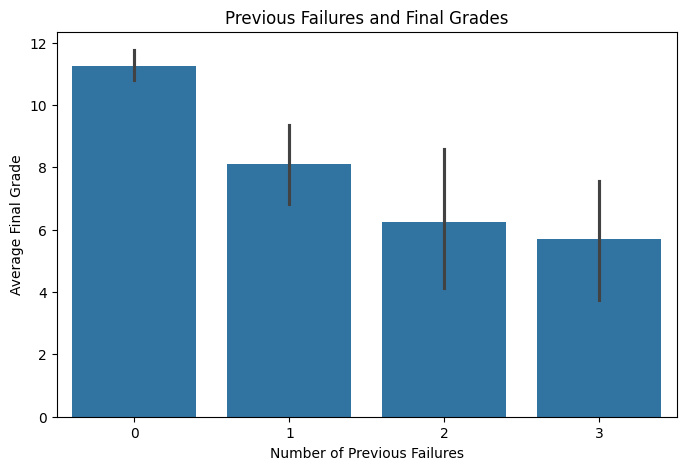

Average final grade: 10.42

Average grades by study time:
studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

Average grades by previous failures:
failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64

Correlation between absences and grades:
0.03424731615006931


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Graph 1: Study time and final grades
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="studytime", y="G3")
plt.title("Study Time and Final Grades")
plt.xlabel("Study Time Category (1-4)")
plt.ylabel("Average Final Grade")
plt.show()

# Graph 2: Absences and final grades
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="absences", y="G3")
plt.title("Absences and Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")
plt.show()

# Graph 3: Previous failures and final grades
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="failures", y="G3")
plt.title("Previous Failures and Final Grades")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Average Final Grade")
plt.show()

# Research results
print("Average final grade:", round(df["G3"].mean(), 2))

print("\nAverage grades by study time:")
print(df.groupby("studytime")["G3"].mean())

print("\nAverage grades by previous failures:")
print(df.groupby("failures")["G3"].mean())

print("\nCorrelation between absences and grades:")
print(df["absences"].corr(df["G3"]))

Average grade: 10.42
Median grade: 11.0
Standard deviation: 4.58


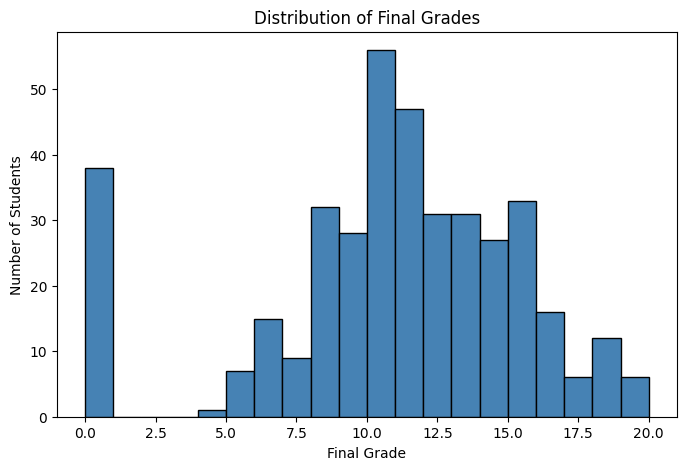

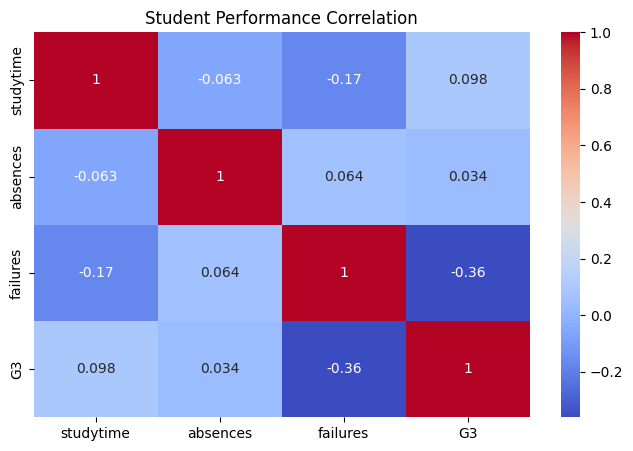

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# NumPy statistical analysis
grades = df["G3"].to_numpy()

print("Average grade:", round(np.mean(grades), 2))
print("Median grade:", np.median(grades))
print("Standard deviation:", round(np.std(grades), 2))

# Matplotlib grade distribution
plt.figure(figsize=(8, 5))
plt.hist(grades, bins=20, color="steelblue", edgecolor="black")
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.show()

# Seaborn correlation heatmap
plt.figure(figsize=(8, 5))
columns = ["studytime", "absences", "failures", "G3"]
sns.heatmap(df[columns].corr(), annot=True, cmap="coolwarm")
plt.title("Student Performance Correlation")
plt.show()
